# Expert Sweep Report Analysis

Concise analysis from `expert_pipeline_report.xlsx`: run matrices, dense plots, matched component-count significance, top-k diagnostics, and final takeaways.

In [1]:
from pathlib import Path
import json
import math
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "configs/pipeline").exists() and (path / "outputs/pipeline_runs").exists()
)

import sys
sys.path.insert(0, str(ROOT))
from pipeline_tools.reporting.significance import build_significance_results

PRIMARY_METRICS = {
    "Belebele": ("acc_norm", "higher"),
    "FLORES": ("bits_per_byte", "lower"),
    "SIB200": ("f1", "higher"),
    "Taxi1500": ("f1", "higher"),
}
BENCHMARKS = list(PRIMARY_METRICS)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180})


def open_report(path):
    xls = pd.ExcelFile(path)
    return xls, {name: pd.read_excel(path, sheet_name=name) for name in xls.sheet_names}


def sheet(sheets, prefix):
    matches = [name for name in sheets if name == prefix or name.startswith(prefix)]
    if not matches:
        raise KeyError(f"No sheet matching {prefix!r}; available={list(sheets)}")
    return sheets[matches[0]].copy()


def clean_bool(series):
    return series.astype(str).str.lower().isin(["true", "yes", "1"])


def normalize_raw(raw):
    raw = raw.copy()
    raw = raw[~clean_bool(raw.get("is_baseline", pd.Series(False, index=raw.index)))].copy()
    wanted = []
    for benchmark, (metric, better) in PRIMARY_METRICS.items():
        part = raw[(raw.benchmark.eq(benchmark)) & (raw.metric.eq(metric))].copy()
        part["better"] = better
        wanted.append(part)
    metrics = pd.concat(wanted, ignore_index=True)
    metrics["value"] = pd.to_numeric(metrics["value"], errors="coerce")
    metrics = metrics.dropna(subset=["value"])

    group_cols = ["benchmark", "task", "metric"]
    lo = metrics.groupby(group_cols)["value"].transform("min")
    hi = metrics.groupby(group_cols)["value"].transform("max")
    span = hi - lo
    higher = (metrics["value"] - lo) / span
    lower = (hi - metrics["value"]) / span
    metrics["normalized_score"] = np.where(metrics["better"].eq("lower"), lower, higher)
    metrics.loc[(~np.isfinite(span)) | span.eq(0), "normalized_score"] = 1.0
    return metrics


def run_scores(metrics, extra_cols):
    index_cols = ["run_id", "kind", *extra_cols]
    scores = (
        metrics.groupby(index_cols + ["benchmark"], dropna=False)["normalized_score"]
        .mean()
        .unstack("benchmark")
        .reindex(columns=BENCHMARKS)
    )
    scores["aggregate_score"] = scores[BENCHMARKS].mean(axis=1)
    return scores.reset_index().sort_values("aggregate_score", ascending=False)


def exact_scores(metrics, extra_cols):
    frame = metrics.copy()
    frame["exact_value"] = np.where(frame.benchmark.eq("FLORES"), 2 ** frame.value, frame.value)
    return (
        frame.groupby(["run_id", "kind", *extra_cols, "benchmark"], dropna=False)["exact_value"]
        .mean()
        .unstack("benchmark")
        .reindex(columns=BENCHMARKS)
        .reset_index()
    )


def status_style(value):
    value = str(value)
    if value in {"complete_clean", "selected", "done", "yes"}:
        return "background-color: #c6efce; color: #006100"
    if value in {"not_computed", "not planned", "missing"}:
        return "background-color: #eeeeee; color: #666666"
    if "probe" in value or "short" in value or "incomplete" in value:
        return "background-color: #f4cccc; color: #990000"
    return "background-color: #ffeb9c; color: #9c6500"


def friedman_rows(significance, prefix):
    rows = []
    for item in significance.get("friedman_results", []):
        row = {
            "group_label": item.get("group_label"),
            "n_units": item.get("n_units"),
            "n_algorithms": item.get("n_algorithms"),
            "p_fdr": item.get("p_fdr"),
            "kendalls_w": item.get("kendalls_w"),
            "best_level": str(item.get("best_rank_approach", "")).replace(prefix, ""),
            "best_avg_rank": item.get("best_avg_rank"),
            "unique_winner_fdr": item.get("unique_winner_fdr"),
        }
        rows.append(row)
    return pd.DataFrame(rows)


def pairwise_rows(significance, prefix):
    rows = []
    for item in significance.get("pairwise_results", []):
        row = dict(item)
        row["label_a"] = str(row.get("label_a", "")).replace(prefix, "")
        row["label_b"] = str(row.get("label_b", "")).replace(prefix, "")
        rows.append(row)
    return pd.DataFrame(rows)

REPORT = ROOT / "outputs/pipeline_runs/moe_study_expert_sweep_pipeline_report/expert_pipeline_report.xlsx"
xls, sheets = open_report(REPORT)
raw = sheet(sheets, "benchmark_raw")
source = sheet(sheets, "source_manifest")
audit = sheet(sheets, "audit_status")
count_summary_sheet = sheet(sheets, "expert_selection_expert_count")
kind_summary_sheet = sheet(sheets, "expert_selection_kind_expert")
large_topk_sheet = sheet(sheets, "expert_selection_large_topk_sum")
print(REPORT)
print(xls.sheet_names)

/local/joeldag/repos/moe-study/outputs/pipeline_runs/moe_study_expert_sweep_pipeline_report/expert_pipeline_report.xlsx
['benchmark_compact', 'data_overview', 'run_configs', 'pipeline_profile', 'benchmark_raw', 'experiment_meta', 'source_manifest', 'audit_status', 'expert_selection_expert_count_s', 'expert_selection_kind_expert_su', 'expert_selection_kind_exact_sum', 'expert_selection_large_topk_sum', 'expert_selection_large_topk_exa', 'expert_selection_routed_moe_cou']


## Run Matrices

Component count means experts, heads, up-projections, CoLA-B, or dense MoV experts. The axis label is kept visible.

In [2]:
COUNTS = [2, 4, 8, 16, 32]
E_RE = re.compile(r"_e(\d+)(?:_|$)")
K_RE = re.compile(r"_k(\d+)(?:_|$)")
HEADS_RE = re.compile(r"_heads(\d+)$")
NUP_RE = re.compile(r"_nup(\d+)$")
COLA_RE = re.compile(r"_b(\d+)$")


def parse_component(run_id):
    run_id = str(run_id)
    for regex in [E_RE, HEADS_RE, NUP_RE, COLA_RE]:
        m = regex.search(run_id)
        if m:
            return int(m.group(1))
    return np.nan


def parse_topk(run_id):
    m = K_RE.search(str(run_id))
    return int(m.group(1)) if m else np.nan


def axis_label(kind, run_id):
    run_id = str(run_id)
    if kind == "hydralora":
        return "heads"
    if kind == "mtllora":
        return "up_projections"
    if kind == "cola":
        return "cola_B"
    return "experts"

status_rows = pd.concat([source, audit], ignore_index=True, sort=False)
status_rows["component_count"] = status_rows.run_id.map(parse_component)
status_rows["top_k"] = status_rows.run_id.map(parse_topk)
status_rows = status_rows[status_rows.component_count.notna()].copy()
status_rows["axis_label"] = [axis_label(k, r) for k, r in zip(status_rows.kind, status_rows.run_id)]
status_rows["row_label"] = status_rows.kind + " / " + status_rows.axis_label
status_rows["matrix_status"] = np.where(clean_bool(status_rows.get("selected_for_main", pd.Series(False, index=status_rows.index))), "complete_clean", status_rows.status.fillna("missing"))
status_rank = {"complete_clean": 0, "probe_or_incomplete": 1, "short_probe_not_valid": 1, "not_computed": 2}
status_rows["priority"] = status_rows.matrix_status.map(status_rank).fillna(1)
status_rows = status_rows.sort_values("priority").drop_duplicates(["row_label", "component_count"], keep="first")
component_matrix = (
    status_rows.assign(component_count=lambda df: df.component_count.astype(int))
    .pivot_table(index="row_label", columns="component_count", values="matrix_status", aggfunc="first")
    .reindex(columns=COUNTS)
    .fillna("not planned")
)
display(component_matrix.style.map(status_style))

topk_rows = status_rows[status_rows.top_k.notna()].copy()
topk_rows["row_label"] = topk_rows.kind + " e" + topk_rows.component_count.astype(int).astype(str)
topk_matrix = topk_rows.pivot_table(index="row_label", columns="top_k", values="matrix_status", aggfunc="first").fillna("not planned")
display(topk_matrix.style.map(status_style))

component_count,2,4,8,16,32
row_label,,,,,
adamole / experts,complete_clean,complete_clean,complete_clean,complete_clean,not_computed
cola / cola_B,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
hmora / experts,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
hydralora / heads,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
moelora / experts,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
mola / experts,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
movlora / experts,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean
mtllora / up_projections,complete_clean,complete_clean,complete_clean,complete_clean,complete_clean


top_k,1.000000
row_label,
hmora e16,complete_clean
hmora e2,complete_clean
hmora e32,complete_clean
hmora e4,complete_clean
hmora e8,complete_clean
moelora e16,complete_clean
moelora e2,complete_clean
moelora e32,complete_clean
moelora e4,complete_clean


## Scores and Dense Views

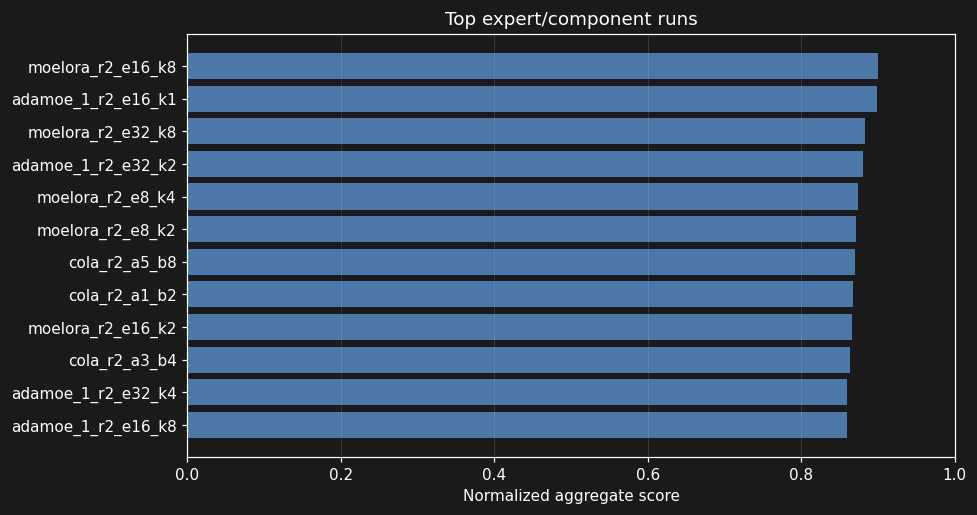

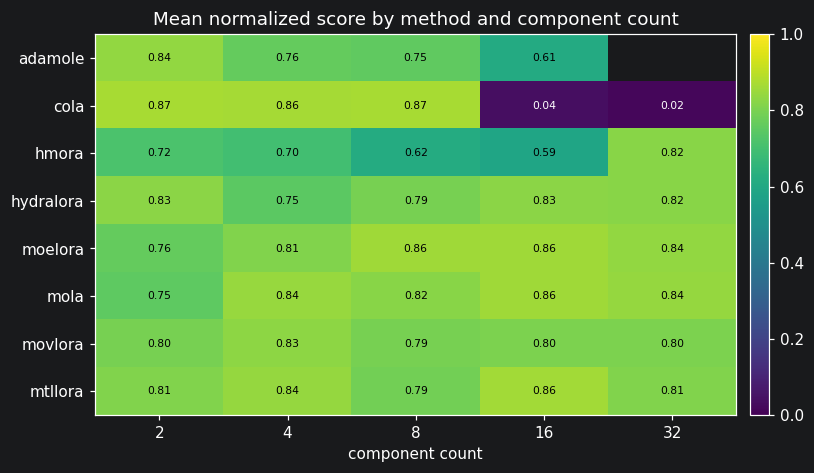

In [3]:
metrics = normalize_raw(raw)
metrics["component_count"] = metrics.run_id.map(parse_component)
metrics["top_k"] = metrics.run_id.map(parse_topk)
metrics["axis_label"] = [axis_label(k, r) for k, r in zip(metrics.kind, metrics.run_id)]
metrics = metrics[metrics.component_count.notna()].copy()
metrics["component_count"] = metrics.component_count.astype(int)
scores = run_scores(metrics, ["component_count", "top_k", "axis_label"])
exact = exact_scores(metrics, ["component_count", "top_k", "axis_label"])

fig, ax = plt.subplots(figsize=(9, 5))
top = scores.head(12).iloc[::-1]
ax.barh(top.run_id, top.aggregate_score, color="#4C78A8")
ax.set(xlabel="Normalized aggregate score", title="Top expert/component runs", xlim=(0, 1))
ax.grid(axis="x", alpha=0.25)
plt.show()

heat = scores.pivot_table(index="kind", columns="component_count", values="aggregate_score", aggfunc="mean").reindex(columns=COUNTS)
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(heat, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(heat.columns)), [str(c) for c in heat.columns])
ax.set_yticks(range(len(heat.index)), heat.index)
ax.set(title="Mean normalized score by method and component count", xlabel="component count")
for y, row in enumerate(heat.index):
    for x, col in enumerate(heat.columns):
        val = heat.loc[row, col]
        if pd.notna(val):
            ax.text(x, y, f"{val:.2f}", ha="center", va="center", fontsize=7, color="white" if val < 0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
plt.show()

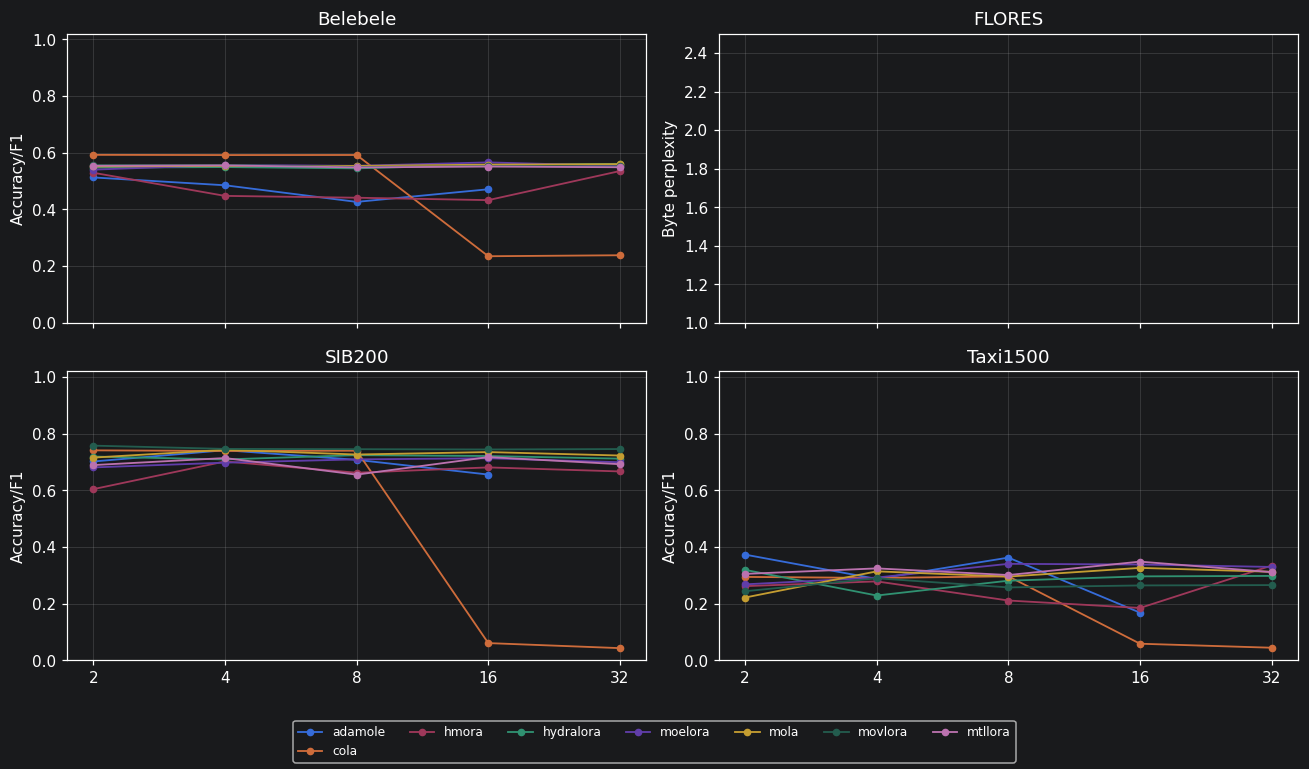

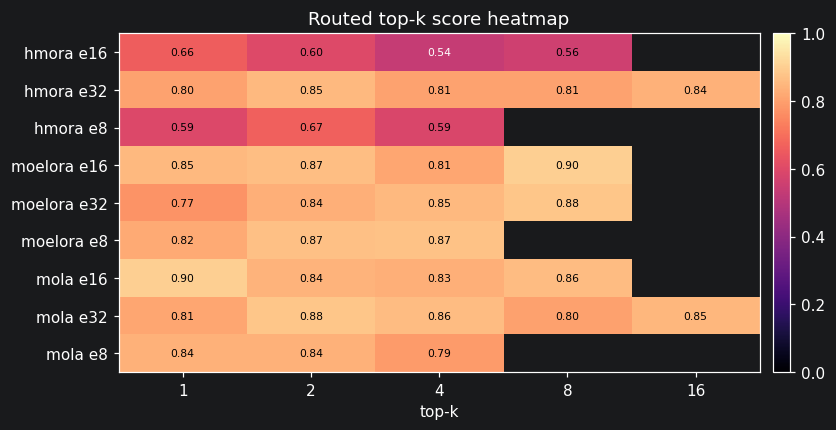

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
fields = [("Belebele", "Accuracy/F1"), ("FLORES", "Byte perplexity"), ("SIB200", "Accuracy/F1"), ("Taxi1500", "Accuracy/F1")]
exact_by_kind = exact.groupby(["kind", "component_count"], as_index=False)[BENCHMARKS].mean()
for ax, (bench, ylabel) in zip(axes.flat, fields):
    for kind, group in exact_by_kind.groupby("kind"):
        group = group.sort_values("component_count")
        y = group[bench]
        if bench == "FLORES":
            y = y.clip(upper=2.5)
        ax.plot(group.component_count, y, marker="o", linewidth=1.2, markersize=4, label=kind)
    ax.set_xscale("log", base=2)
    ax.set_xticks(COUNTS)
    ax.set_xticklabels([str(c) for c in COUNTS])
    ax.set_title(bench)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    if bench == "FLORES":
        ax.set_ylim(1.0, 2.5)
    else:
        ax.set_ylim(0, 1.02)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=7, fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

large = scores[scores.component_count.isin([8, 16, 32]) & scores.top_k.notna()].copy()
large["row"] = large.kind + " e" + large.component_count.astype(int).astype(str)
topk_heat = large.pivot_table(index="row", columns="top_k", values="aggregate_score", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8, max(4, 0.35 * len(topk_heat))))
im = ax.imshow(topk_heat, aspect="auto", cmap="magma", vmin=0, vmax=1)
ax.set_xticks(range(len(topk_heat.columns)), [str(int(c)) for c in topk_heat.columns])
ax.set_yticks(range(len(topk_heat.index)), topk_heat.index)
ax.set(title="Routed top-k score heatmap", xlabel="top-k")
for y, row in enumerate(topk_heat.index):
    for x, col in enumerate(topk_heat.columns):
        val = topk_heat.loc[row, col]
        if pd.notna(val):
            ax.text(x, y, f"{val:.2f}", ha="center", va="center", fontsize=7, color="white" if val < 0.55 else "black")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
plt.show()

## Significance

Primary test: component counts `2, 4, 8, 16, 32` using matched method/axis variants. Top-k is exploratory and keeps component count fixed.

In [5]:
def complete_component_methods(frame, counts):
    by_method = defaultdict(set)
    for row in frame.itertuples(index=False):
        if pd.notna(row.top_k) and int(row.top_k) != 1:
            continue
        variant = "topk1" if pd.notna(row.top_k) else row.axis_label
        by_method[f"{row.kind}:{variant}"].add(int(row.component_count))
    return {method for method, seen in by_method.items() if all(count in seen for count in counts)}


def component_payload(frame, counts):
    labels = [f"component_{count}" for count in counts]
    methods = complete_component_methods(frame, counts)
    by_unit = defaultdict(dict)
    for row in frame.itertuples(index=False):
        if int(row.component_count) not in counts:
            continue
        if pd.notna(row.top_k) and int(row.top_k) != 1:
            continue
        variant = "topk1" if pd.notna(row.top_k) else row.axis_label
        method = f"{row.kind}:{variant}"
        if method not in methods:
            continue
        key = (method, row.benchmark, row.task, row.metric, row.better)
        by_unit[key][int(row.component_count)] = row
    table_rows = []
    for (_method, benchmark, task, metric, better), count_rows in sorted(by_unit.items()):
        if all(count in count_rows for count in counts):
            table_rows.append({
                "benchmark": benchmark,
                "metric_family": metric,
                "task": task,
                "better": better,
                "approach_values": {f"component_{count}": float(count_rows[count].value) for count in counts},
            })
    return {"algorithm_labels": labels, "table_rows": table_rows, "included_method_variants": sorted(methods)}


def topk_payload(frame, counts):
    topk_by_count = defaultdict(set)
    for row in frame[frame.top_k.notna()].itertuples(index=False):
        if int(row.component_count) in counts:
            topk_by_count[int(row.component_count)].add(int(row.top_k))
    common_topk = sorted(set.intersection(*(topk_by_count[count] for count in counts if topk_by_count[count])))
    by_unit = defaultdict(dict)
    for row in frame[frame.top_k.notna()].itertuples(index=False):
        count, topk = int(row.component_count), int(row.top_k)
        if count not in counts or topk not in common_topk:
            continue
        key = (row.kind, count, row.benchmark, row.task, row.metric, row.better)
        by_unit[key][topk] = row
    table_rows = []
    for (_kind, _count, benchmark, task, metric, better), rows in sorted(by_unit.items()):
        if all(topk in rows for topk in common_topk):
            table_rows.append({
                "benchmark": benchmark,
                "metric_family": metric,
                "task": task,
                "better": better,
                "approach_values": {f"topk_{topk}": float(rows[topk].value) for topk in common_topk},
            })
    return {"algorithm_labels": [f"topk_{topk}" for topk in common_topk], "table_rows": table_rows}

component_sig = build_significance_results(component_payload(metrics, COUNTS))
component_friedman = friedman_rows(component_sig, "component_")
topk_sig = build_significance_results(topk_payload(metrics, [8, 16, 32]))
topk_friedman = friedman_rows(topk_sig, "topk_")

display(component_friedman)
display(topk_friedman)

,group_label,n_units,n_algorithms,p_fdr,kendalls_w,best_level,best_avg_rank,unique_winner_fdr
0,Belebele,63,5,0.050779,0.041367,4,2.706349,False
1,SIB200,63,5,0.001362,0.080197,16,2.539683,False
2,Taxi1500,42,5,0.056778,0.054637,16,2.464286,False


,group_label,n_units,n_algorithms,p_fdr,kendalls_w,best_level,best_avg_rank,unique_winner_fdr
0,Belebele,81,3,0.082215,0.030845,4,1.833333,False
1,SIB200,81,3,0.000450,0.100137,4,1.703704,True
2,Taxi1500,54,3,0.000042,0.206790,2,1.500000,True


## Takeaway

In [6]:
best_count = count_summary_sheet.sort_values("mean_aggregate_score", ascending=False).iloc[0]
best_run = scores.iloc[0]
unique_components = component_friedman[component_friedman.unique_winner_fdr.eq(True)]
unique_topk = topk_friedman[topk_friedman.unique_winner_fdr.eq(True)]
print(f"Best mean component count: {int(best_count.expert_count)} (mean score={best_count.mean_aggregate_score:.4f})")
print(f"Best single expert/component run: {best_run.run_id} (count={int(best_run.component_count)}, top_k={best_run.top_k}, score={best_run.aggregate_score:.4f})")
print("Unique significant component-count winners:", ", ".join(f"{r.group_label}: count {r.best_level}" for r in unique_components.itertuples()) or "none")
print("Exploratory unique top-k winners:", ", ".join(f"{r.group_label}: top-k {r.best_level}" for r in unique_topk.itertuples()) or "none")

Best mean component count: 2 (mean score=0.8468)
Best single expert/component run: moelora_r2_e16_k8 (count=16, top_k=8.0, score=0.9004)
Unique significant component-count winners: none
Exploratory unique top-k winners: SIB200: top-k 4, Taxi1500: top-k 2
